# General relativity 8: Gravitational waves

*Learning path: general relativity, part 8 of 9.* [Index](README.md) · Previous: [Clocks and GPS](07-clocks-and-gps.ipynb) · Next: [Cosmology](09-cosmology.ipynb)

In 1916 Einstein predicted that accelerating masses send out ripples in the curvature of spacetime, travelling at the
speed of light. A century later, on 14 September 2015, the LIGO detectors recorded one from two black holes merging
1.3 billion light years away. You will learn

* an exact gravitational wave solution of Einstein's equations, checked with Galileo,
* what a passing wave does to a ring of free particles,
* why detecting one means measuring a length change of a thousandth of a proton,
* the "chirp" of two black holes spiralling together.

## 1. An exact plane wave

A plane wave travelling in the $z$ direction is simplest in *light-cone* coordinates $u = t - z$, $v$, and the
transverse $x$, $y$. The metric

$$ds^2 = H(u, x, y)\,du^2 + 2\,du\,dv + dx^2 + dy^2, \qquad H = h\cos(u)\,(x^2 - y^2)$$

describes a wave of the profile $\cos u$ and amplitude $h$. Is it a solution of Einstein's vacuum equations?

In [1]:
pp = metric([u v x y], [h*cos(u)*(x^2-y^2) 1 0 0; 1 0 0 0; 0 0 1 0; 0 0 0 1])
riccitensor(pp)

$$ds^2 = h \cos\left(u\right) \left(x^{2} - y^{2}\right)\, du^2 + 2\, du\, dv + \, dx^2 + \, dy^2$$

**Ricci tensor** (coordinates $u$, $v$, $x$, $y$)

$$\begin{aligned}
R = 0 \quad\text{(all components)}
\end{aligned}$$

Yes: Ricci-flat, so it needs no matter as a source; it travels on its own. Yet spacetime is curved, and the curvature
travels with the wave:

In [2]:
riemannsecond(pp)

**Riemann curvature tensor** (coordinates $u$, $v$, $x$, $y$)

$$\begin{aligned}
R{}^{v}{}_{x}{}_{u}{}_{x} &= -h \cos\left(u\right) \\
R{}^{v}{}_{y}{}_{u}{}_{y} &= h \cos\left(u\right) \\
R{}^{x}{}_{u}{}_{u}{}_{x} &= h \cos\left(u\right) \\
R{}^{y}{}_{u}{}_{u}{}_{y} &= -h \cos\left(u\right)
\end{aligned}$$

(This works because $\partial_x^2 H + \partial_y^2 H = 2 - 2 = 0$. Try $H = h\cos(u)(x^2 + y^2)$ and the Ricci tensor is
no longer zero.)

## 2. A ring of particles

The geodesic equations show what the wave does to free particles:

In [3]:
geodesics(pp)

**Geodesic equations (' = d/ds along the curve)**

$$\begin{aligned}
\mathrm{u''} &= 0 \\
\mathrm{v''} &= \frac{h \mathrm{u'} \left(\sin\left(u\right) \mathrm{u'} x^{2} - \sin\left(u\right) \mathrm{u'} y^{2} - 4 x \cos\left(u\right) \mathrm{x'} + 4 y \cos\left(u\right) \mathrm{y'}\right)}{2} \\
\mathrm{x''} &= h \cos\left(u\right) \mathrm{u'}^{2} x \\
\mathrm{y''} &= -h \cos\left(u\right) \mathrm{u'}^{2} y
\end{aligned}$$

$\ddot x = h\cos(u)\,\dot u^2\,x$ and $\ddot y = -h\cos(u)\,\dot u^2\,y$: when the wave stretches $x$ it squeezes $y$, and
half a period later the other way round. This pattern is the **plus** polarisation; a wave with $H \propto 2xy$
(the **cross** polarisation) does the same along the diagonals.

Here are eight free particles on a ring of radius 1, followed as the wave passes, with $h = 0.1$. Time ($u$) runs
upward, so each particle traces a worldline and together they form a tube that bulges and pinches:

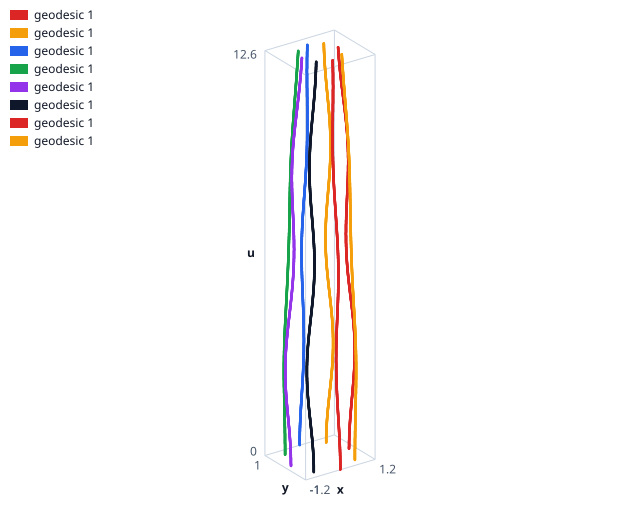

In [4]:
h = 0.1;
p1 = geodesic(pp, [0, 0, 1, 0], [1, -0.5, 0, 0], 12.6, [x y u]);
p2 = geodesic(pp, [0, 0, 0.707, 0.707], [1, -0.5, 0, 0], 12.6, [x y u]);
p3 = geodesic(pp, [0, 0, 0, 1], [1, -0.5, 0, 0], 12.6, [x y u]);
p4 = geodesic(pp, [0, 0, -0.707, 0.707], [1, -0.5, 0, 0], 12.6, [x y u]);
p5 = geodesic(pp, [0, 0, -1, 0], [1, -0.5, 0, 0], 12.6, [x y u]);
p6 = geodesic(pp, [0, 0, -0.707, -0.707], [1, -0.5, 0, 0], 12.6, [x y u]);
p7 = geodesic(pp, [0, 0, 0, -1], [1, -0.5, 0, 0], 12.6, [x y u]);
p8 = geodesic(pp, [0, 0, 0.707, -0.707], [1, -0.5, 0, 0], 12.6, [x y u]);
show(p1, p2, p3, p4, p5, p6, p7, p8)

Following just two particles, the one on the $x$ axis and the one on the $y$ axis, and plotting their distance from the
centre:

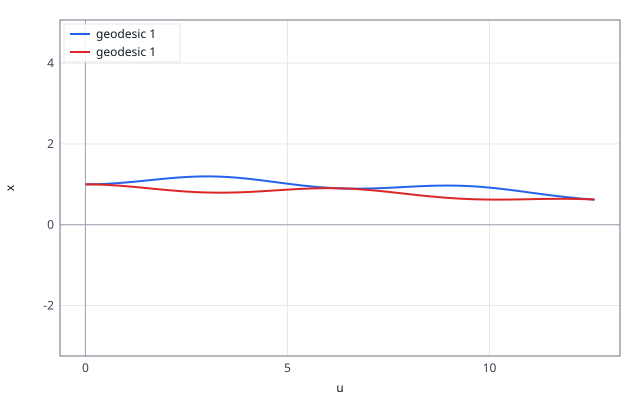

In [5]:
px = geodesic(pp, [0, 0, 1, 0], [1, -0.5, 0, 0], 12.6, [u x]);
py = geodesic(pp, [0, 0, 0, 1], [1, -0.5, 0, 0], 12.6, [u y]);
show(px, py)

The two oscillate in opposite phase: while one moves out, the other moves in. Both also drift slowly inward. That is
a second-order effect, proportional to $h^2$: the energy carried by the wave itself focuses the particles. With our
exaggerated $h = 0.1$ it is visible; for real waves, with $h \approx 10^{-21}$, it is utterly negligible.

A LIGO detector is exactly this: two perpendicular 4 km arms with free-hanging mirrors at the ends. Laser light measures
the difference in arm length, which a passing wave makes oscillate.

## 3. How small?

Real waves reaching Earth have $h \approx 10^{-21}$. The change in a 4 km arm, compared with the size of a proton:

In [6]:
dL = eval(1e-21*4000/2)
eval(dL/0.84e-15)

1.9999999999999998E-18
0.0023809523809523807

A change of about one thousandth of a proton radius. LIGO reaches this by bouncing the light back and forth hundreds of
times, using 200 kW of circulating laser power, and isolating the mirrors from ground vibrations.

## 4. The chirp

Two black holes in orbit lose energy to gravitational waves, so they spiral together, orbiting ever faster. The wave
frequency rises as the merger approaches, a *chirp*. To leading order, a time $\tau$ before the merger the frequency is

$$f = \frac{1}{\pi}\left(\frac{5}{256\,\tau}\right)^{3/8}\left(\frac{G\mathcal M}{c^3}\right)^{-5/8}$$

where $\mathcal M$ is the *chirp mass*. For the first detection, GW150914, $\mathcal M \approx 28$ solar masses, so
$G\mathcal M/c^3 = 28 \times 4.925\,\mu\text{s}$. The frequency during the last 0.2 seconds (time $t = -\tau$):

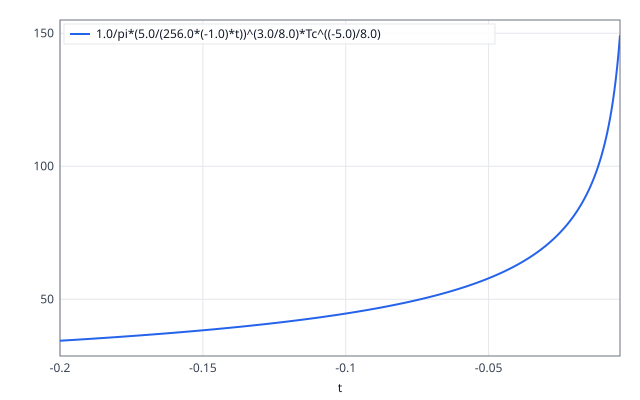

In [7]:
Tc = 28*4.925e-6;
plot(1/pi*(5/(256*(-t)))^(3/8)*Tc^(-5/8), t, -0.2, -0.004)

From about 35 Hz to over 150 Hz in a fifth of a second, the range LIGO heard (it is audible if played as sound). The
signal stops at the merger, when the two black holes become one. That final black hole was about 3 solar masses lighter
than the two together: that mass was radiated as gravitational waves, in joules:

In [8]:
eval(3*1.989e30*299792458^2)

5.36287215152259E47

About $5\times10^{47}$ J in a fraction of a second, more power than all the stars in the observable universe combined.

## Summary

* Gravitational waves are vacuum solutions: curvature that travels at the speed of light.
* A passing wave stretches and squeezes free particles at right angles (plus and cross polarisations).
* The strain is about $10^{-21}$: LIGO measures arm changes of $10^{-18}$ m.
* Merging black holes produce a chirp whose frequency sweep gives their chirp mass.

Next: [Cosmology](09-cosmology.ipynb): the metric of the whole universe.